In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## load dataset:

In [2]:
# 1.
load=pd.read_csv('clean_repair_cost_predict.csv')

In [3]:
load['failure_flag']=load[['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF']].max(axis=1)

In [4]:
load.drop(['Product ID','Machine failure','TWF','HDF','PWF','OSF','RNF','UDI'],axis=1,inplace=True)

In [5]:
load=pd.get_dummies(load,drop_first=True).astype(int)

______________________________________________________________________________________________________________________________________________

## model creation and DS concepts:

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [7]:
from sklearn.metrics import classification_report,confusion_matrix

In [8]:
# 2.
x=load.drop('failure_flag',axis=1)
y=load['failure_flag']

In [9]:
# 3.
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.75,random_state=42)

### Tuning  rf model:

In [10]:
# rf=RandomForestClassifier(class_weight='balanced',random_state=42)
# model_pred=rf.fit(xtrain,ytrain).predict(xtest)
# cm=confusion_matrix(ytest,model_pred)
# cm
# cls=classification_report(ytest,model_pred)
# print(cls)

______________________________________________________________________________________________________________________________________________

In [11]:
data=load['failure_flag'].value_counts()

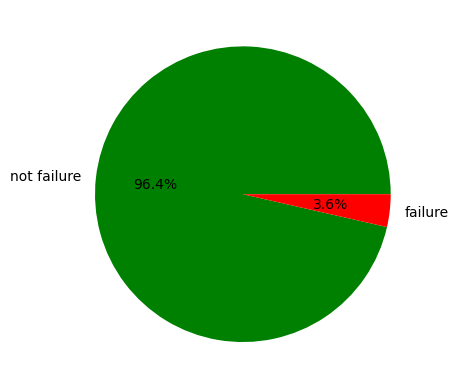

In [12]:
plt.pie(data.values,labels=['not failure','failure'],autopct="%1.1f%%",colors=['green','red'])
plt.show()

______________________________________________________________________________________________________________________________________________

# handle imbalanced data:


## over sampling:

In [13]:
from imblearn.over_sampling import RandomOverSampler

In [14]:
# 4.
over=RandomOverSampler()
x_re,y_re=over.fit_resample(x_train,y_train)
rf=RandomForestClassifier()
fit=rf.fit(x_re,y_re)
y_pred=fit.predict(x_test)

## oversample accuracy:

In [15]:
cm=confusion_matrix(y_test,y_pred)
cm

array([[2392,   30],
       [  45,   33]])

In [16]:
# cls=classification_report(ytest,ypred)
# print(cls)

------------------------------------------------------------------------------------------------------------------------
------------------------------------------------------------------------------------------------------------------------

# Feature Selection:

In [17]:
from sklearn.feature_selection import SelectKBest,chi2

In [18]:
def features(xtrain,ytrain,xtest,n):
    kb=SelectKBest(score_func=chi2,k=n)
    x_train_fe=kb.fit_transform(xtrain,ytrain)
    x_test_fe=kb.transform(xtest)
    mask=kb.get_support()
    selected_features=xtrain.columns[mask]
    
    return x_train_fe,x_test_fe,selected_features

In [19]:
from sklearn.metrics import accuracy_score
def acc(classifier,ytest,xtest):
    ypred=classifier.predict(xtest)
    ac=accuracy_score(ytest,ypred)
    cm,report=clf(ytest,ypred)
    return ac,cm,report
    

In [20]:
def clf(ytest,ypred):
    cm=confusion_matrix(ytest,ypred)
    clfs=classification_report(ytest,ypred)
    return cm,clfs

In [21]:
def model_creation(model,xtrain,ytrain,xtest,ytest):
    classifier=model.fit(xtrain,ytrain)
    accuracy,cm,rep=acc(classifier,ytest,xtest)
    return round(accuracy,2),cm,rep
    
    

In [22]:
# import models:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [23]:
dt=DecisionTreeClassifier(class_weight='balanced',max_depth=3)
rt=RandomForestClassifier(class_weight='balanced')
svm=SVC(class_weight='balanced')
xg=XGBClassifier()

In [24]:
models=[dt,rt,svm,xg]

In [25]:
# mask=kb.get_support()
# cols=x_re.columns[mask]
# cols

In [26]:
xtrain,xtest,features=features(x_re,y_re,x_test,5)

In [27]:
score=[]
for model in models:
    accs,cm,clf_rep=model_creation(model,xtrain,y_re,xtest,y_test)
    score.append(accs)
    print(f'{model} : {accs}')
    print(cm)
    print()
    print(clf_rep)
    print('\n\n')

DecisionTreeClassifier(class_weight='balanced', max_depth=3) : 0.87
[[2119  303]
 [  19   59]]

              precision    recall  f1-score   support

           0       0.99      0.87      0.93      2422
           1       0.16      0.76      0.27        78

    accuracy                           0.87      2500
   macro avg       0.58      0.82      0.60      2500
weighted avg       0.97      0.87      0.91      2500




RandomForestClassifier(class_weight='balanced') : 0.97
[[2392   30]
 [  44   34]]

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2422
           1       0.53      0.44      0.48        78

    accuracy                           0.97      2500
   macro avg       0.76      0.71      0.73      2500
weighted avg       0.97      0.97      0.97      2500




SVC(class_weight='balanced') : 0.83
[[2011  411]
 [  20   58]]

              precision    recall  f1-score   support

           0       0.99      0.83      0.9

In [28]:
score

[0.87, 0.97, 0.83, 0.95]

In [29]:
features

Index(['Air temperature [K]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L',
       'Type_M'],
      dtype='object')

In [30]:
feature_df=pd.DataFrame(columns=features)    

In [31]:
feature_df

,Air temperature [K],Torque [Nm],Tool wear [min],Type_L,Type_M


In [32]:
for i in features:
    feature_df[i]=load[i].values

In [33]:
feature_df

,Air temperature [K],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298,42,0,0,1
1,298,46,3,1,0
2,298,49,5,1,0
3,298,39,7,1,0
4,298,40,9,1,0
...,...,...,...,...,...
9995,298,29,14,0,1
9996,298,31,17,0,0
9997,299,33,22,0,1
9998,299,48,25,0,0


# ADA BOOST :

In [34]:
from sklearn.ensemble import AdaBoostClassifier

In [35]:
ada=AdaBoostClassifier(estimator=dt,learning_rate=1.0,n_estimators=200)
fits=ada.fit(xtrain,y_re)
predicted=fits.predict(xtest)
cm=confusion_matrix(y_test,predicted)
print(cm)
print(classification_report(y_test,predicted))

[[2203  219]
 [  20   58]]
              precision    recall  f1-score   support

           0       0.99      0.91      0.95      2422
           1       0.21      0.74      0.33        78

    accuracy                           0.90      2500
   macro avg       0.60      0.83      0.64      2500
weighted avg       0.97      0.90      0.93      2500



In [36]:
from sklearn.model_selection import GridSearchCV

In [37]:
params={'n_estimators':[10,50,100,200],'learning_rate':[0.01,0.05,0.1,0.5,1.0],}

In [38]:
grid=GridSearchCV(ada,param_grid=params,cv=5,refit=True,verbose=3,n_jobs=-1,scoring='f1')

In [39]:
grid.fit(xtrain,y_re)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


GridSearchCV(cv=5,
             estimator=AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                           max_depth=3),
                                          n_estimators=200),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
                         'n_estimators': [10, 50, 100, 200]},
             scoring='f1', verbose=3)

In [40]:
grid.best_params_

{'learning_rate': 1.0, 'n_estimators': 200}

In [41]:
re=grid.cv_results_
grid_df=pd.DataFrame(re)

In [42]:
# grid_df

Parameter	Values
n_estimators	100, 200, 300
max_depth	3, 4, 5, 7
learning_rate	0.01, 0.05, 0.1, 0.2
min_child_weight	1, 3, 5
subsample	0.7, 0.8, 1.0
colsample_bytree	0.7, 0.8, 1.0
gamma	0, 0.1, 0.2
reg_alpha	0, 0.01, 0.1
reg_lambda	1, 5, 10

In [44]:
params2={'n_estimators':[100,200,300],
        'max_depth':[3,4,5,7],
        'learning_rate':[0.01,0.05,0.1,0.2],}
grid2=GridSearchCV(xg,param_grid=params2,refit=True,cv=4,scoring='f1',verbose=3,n_jobs=-1)

In [45]:
grid2.fit(xtrain,y_re)

Fitting 4 folds for each of 48 candidates, totalling 192 fits


GridSearchCV(cv=4,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None...
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.05, 0.1, 0.2],
                         'max_depth': [3, 4, 5, 7],
                         'n_estimators': [100, 200, 300]},
             scoring='f1', verbose=3)

In [46]:
re2=grid2.cv_results_
grid_df2=pd.DataFrame(re2)

In [54]:
# grid_df2

In [49]:
grid2.best_params_

{'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 300}

# XG-BOOST :

In [51]:
xg=XGBClassifier(learning_rate=0.2,max_depth= 7,n_estimators= 300)
fits=xg.fit(xtrain,y_re)
predicted=fits.predict(xtest)
cm=confusion_matrix(y_test,predicted)
print(cm)
print(classification_report(y_test,predicted))

[[2363   59]
 [  40   38]]
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      2422
           1       0.39      0.49      0.43        78

    accuracy                           0.96      2500
   macro avg       0.69      0.73      0.71      2500
weighted avg       0.96      0.96      0.96      2500



In [52]:
y_re.shape

(14442,)

In [53]:
y_test.shape

(2500,)

In [57]:
# Get probability predictions
y_prob = fits.predict_proba(xtest)[:, 1]
# Change threshold
threshold = 0.3
# Generate predictions
y_pred = (y_prob >= threshold).astype(int)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[2341   81]
 [  39   39]]
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      2422
           1       0.33      0.50      0.39        78

    accuracy                           0.95      2500
   macro avg       0.65      0.73      0.68      2500
weighted avg       0.96      0.95      0.96      2500

